
<a href="https://colab.research.google.com/github/CienciaDatosUdea/002_EstudiantesAprendizajeEstadistico/blob/main/semestre2026-1/Laboratorios/Laboratorio_13_Hopfield.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio: Memorias asociativas con redes de Hopfield

## Objetivo

Construir una red de Hopfield capaz de almacenar imágenes binarias y recuperar una imagen original a partir de una versión con ruido.


# Actividades

Para las imágenes dadas, construya un algoritmo que permita recuperar la imagen original a partir de una imagen perturbada.

Debe implementar funciones para:

1. Convertir una imagen binaria en un vector de estados.
2. Calcular la matriz de pesos de Hopfield.
3. Calcular el campo local que siente una neurona.
4. Actualizar el estado de una neurona.
5. Calcular la energía total de la red.
6. Aplicar ruido a una imagen.
7. Recuperar la imagen mediante actualización asincrónica aleatoria.

---

# Modelo de Hopfield

La matriz de pesos se define mediante la regla de Hebb:

$$
w_{ij}=\frac{1}{N}\sum_{\mu=1}^{P}\xi_i^\mu \xi_j^\mu
$$

con:

$$
w_{ii}=0
$$

donde:

- $N$ es el número total de píxeles,
- $P$ es el número de patrones almacenados,
- $\xi^\mu$ es el patrón $\mu$-ésimo.

---

# Campo local

Para una neurona $i$, el campo local es:

$$
h_i=\sum_j w_{ij}s_j
$$

Este campo representa la influencia colectiva que todas las demás neuronas ejercen sobre la neurona $i$.

---

# Regla de actualización

La actualización determinista de Hopfield es:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

Si:

$$
h_i>0
$$

entonces:

$$
s_i=1
$$

Si:

$$
h_i<0
$$

entonces:

$$
s_i=-1
$$

---

# Energía de la red

La energía total del sistema se define como:

$$
E(s)=-\frac{1}{2}\sum_{ij}w_{ij}s_is_j
$$

o equivalentemente:

$$
E(s)=-\frac{1}{2}s^TWs
$$

El proceso de recuperación debe tender a disminuir la energía.

---

# Algoritmo sugerido

Dada una imagen con ruido:

1. Seleccione aleatoriamente un píxel $i$.
2. Calcule el campo local:

$$
h_i=\sum_j w_{ij}s_j
$$

3. Actualice el estado del píxel:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

4. Calcule la nueva energía del sistema:

$$
E(s)=-\frac{1}{2}s^TWs
$$

5. Visite otro píxel aleatoriamente.
6. Repita el proceso hasta que:
   - la imagen deje de cambiar,
   - la energía se estabilice,
   - o se alcance un número máximo de iteraciones.


# Comentario importante

La actualización debe ser preferiblemente **asincrónica y aleatoria**, porque cada vez que se actualiza un píxel, cambia el estado global de la red. Por tanto, el siguiente campo local debe calcularse usando la imagen ya actualizada.

---

# Preguntas guía

1. ¿La energía disminuye durante la recuperación?
2. ¿La red recupera exactamente la imagen original?
3. ¿Qué ocurre si aumenta el nivel de ruido?
4. ¿Qué pasa si se almacenan varias imágenes?
5. ¿Aparecen estados espurios?
6. ¿La recuperación depende del orden en que se actualizan los píxeles?
7. ¿Qué diferencia hay entre actualización sincrónica y asincrónica?

---

# Capacidad de memoria

La capacidad aproximada de una red de Hopfield clásica es:

$$
P_c \approx 0.138N
$$

donde:

- $P_c$ es el número máximo de patrones recuperables,
- $N$ es el número total de neuronas.

Cuando el número de patrones almacenados supera este valor, aparecen errores y estados espurios.




In [3]:
import numpy as np
import matplotlib.pyplot as plt

## Funciones auxiliares (dadas): patrones de prueba y ruido

### `patrones_balanceados(n, m)`

Se crea la función `patrones_balanceados(n, m)`la cual crea 3 imágenes de prueba de tamaño $n \times m$ con valores en $\{-1, +1\}$ (blanco = $+1$, negro = $-1$):

| Patrón | Cómo se construye | Qué se ve |
|---|---|---|
| `horizontal` | todo en $-1$, y las primeras `n//2` filas en $+1$ | mitad de arriba clara, mitad de abajo oscura |
| `vertical` | todo en $-1$, y las primeras `m//2` columnas en $+1$ | mitad izquierda clara, mitad derecha oscura |
| `checker` | `np.indices` da la fila $i$ y la columna $j$ de cada píxel; si $i+j$ es par → $+1$, si es impar → $-1$ | tablero de ajedrez |

Se llaman balanceados porque cada uno tiene la misma cantidad de $+1$ que de $-1$. Además son ortogonales entre sí ($\xi^\mu \cdot \xi^\nu = 0$)


### `agregar_ruido(s, frac, seed)`

Función que simula una imagen distorcionada. Elige al azar una fracción `frac` de los píxeles del vector `s` y les invierte el signo ($+1 \to -1$, $-1 \to +1$).

Paso a paso:
1. `s.copy()`: trabaja sobre una copia para no modificar la imagen original.
2. `n_flip = int(frac * N)`: número de píxeles a voltear (`int` trunca hacia abajo).
3. `np.random.choice(N, n_flip, replace=False)`: escoge `n_flip` posiciones **distintas** (sin repetir).
4. `s_ruido[idx] *= -1`: multiplica esas posiciones por $-1$.
5. `seed`: fija la semilla aleatoria para que el ruido sea reproducible.

**Ejemplo:** $s = (1, -1, 1, 1)$ con `frac = 0.5`, entonces $N = 4$ y se voltean `int(2.0) = 2` píxeles. Si el azar elige las posiciones $[0, 3]$:

$$
(1, -1, 1, 1) \;\longrightarrow\; (-1, -1, 1, -1)
$$

**Observaciones:**
- La función recibe un vector, no una matriz. Por eso antes se aplana la imagen con `np.concat(img)` (o `img.ravel()`).
- Voltear el 50 % deja la imagen completamente aleatoria, y más del 50 % la acerca a su **negativo**. Este detalle importa para la pregunta 3.
- `np.random.seed` cambia la semilla **global** de NumPy, así que también afecta los números aleatorios que se generen después en el notebook.

In [4]:
def patrones_balanceados(n, m):
    horizontal = -np.ones((n, m))
    horizontal[:n//2, :] = 1

    vertical = -np.ones((n, m))
    vertical[:, :m//2] = 1

    checker = np.indices((n, m)).sum(axis=0)
    checker = np.where(checker % 2 == 0, 1, -1)

    return horizontal, vertical, checker

def agregar_ruido(s, frac=0.25, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido

## Funciones de la red

- `pesos_ij(psi, N)`: calcula la matriz de pesos con la regla de Hebb, $w_{ij} = \frac{1}{N}\xi_i\xi_j$, con $w_{ii}=0$. Así la red "memoriza" el patrón `psi`.
- `campo_local(w_ij, estado)`: calcula $h = W s$, el campo local de todas las neuronas a la vez.
- `energiaTotal(estado, campo)`: calcula la energía $E = -\frac{1}{2} s^T h = -\frac{1}{2} s^T W s$.

In [5]:
# Calcular Pesos wij

def pesos_ij(psi, N):
    w = np.zeros((N,N))
    for i in range(0, N):
        for j in range(0, N):
            if ( i!= j ):
                w[i,j]=psi[0][i]*psi[0][j] / N
    return w

# Calcular campo local
def campo_local(w_ij, estado):
    campo = w_ij@estado
    return campo

# Calcular energía total
def energiaTotal(estado, campo):
    energia = -1*(0.5*estado.T@campo)
    return energia


## Patrón a memorizar (10×10)

Se toma el tablero de ajedrez como imagen original, se convierte en un vector de estados de tamaño $N = 100$ y se calcula la matriz de pesos $W$ para que la red lo memorice.

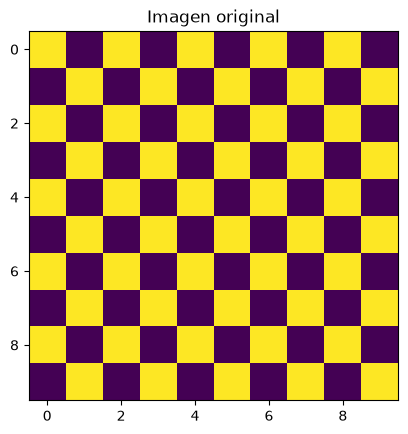

[ 1 -1  1 -1  1 -1  1 -1  1 -1 -1  1 -1  1 -1  1 -1  1 -1  1  1 -1  1 -1
  1 -1  1 -1  1 -1 -1  1 -1  1 -1  1 -1  1 -1  1  1 -1  1 -1  1 -1  1 -1
  1 -1 -1  1 -1  1 -1  1 -1  1 -1  1  1 -1  1 -1  1 -1  1 -1  1 -1 -1  1
 -1  1 -1  1 -1  1 -1  1  1 -1  1 -1  1 -1  1 -1  1 -1 -1  1 -1  1 -1  1
 -1  1 -1  1]
[[ 0.   -0.01  0.01 ...  0.01 -0.01  0.01]
 [-0.01  0.   -0.01 ... -0.01  0.01 -0.01]
 [ 0.01 -0.01  0.   ...  0.01 -0.01  0.01]
 ...
 [ 0.01 -0.01  0.01 ...  0.   -0.01  0.01]
 [-0.01  0.01 -0.01 ... -0.01  0.   -0.01]
 [ 0.01 -0.01  0.01 ...  0.01 -0.01  0.  ]]


In [13]:
# Patrón original y memorización

n = 10        # número de filas
m = 10       # número de columnas
N = n * m    # total de píxeles = número de neuronas (9)

horiz, vert, d = patrones_balanceados(n, m)

# Patrón original como vector (1, N)
psi = np.concat(d).reshape(1, N)

# Memorizar: matriz de pesos (N x N)
w_ij = pesos_ij(psi, N)

plt.imshow(d)
plt.title("Imagen original")
plt.show()
print(psi[0])
print(w_ij)

## Imagen con ruido

Se voltea el 25 % de los píxeles del tablero y se calcula la energía de este estado inicial. Es el punto de partida de la recuperación.

Energía con ruido: -11.999999999999996


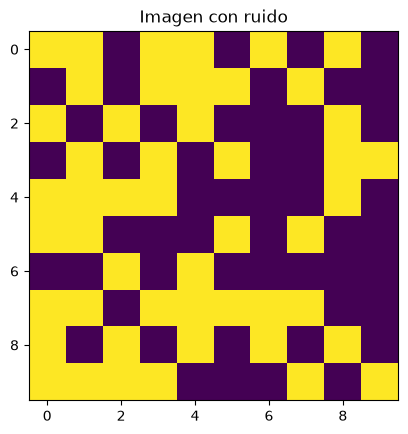

In [5]:
s_ruido = agregar_ruido(np.concat(d), frac=0.25, seed=10)
s_ruido = s_ruido.reshape(N, 1)

# Energía inicial (punto de partida)
campo = campo_local(w_ij, s_ruido)
energia_s_ruido = energiaTotal(s_ruido, campo).item()
print("Energía con ruido:", energia_s_ruido)

plt.imshow(s_ruido.reshape(n, m))
plt.title("Imagen con ruido")
plt.show()

## Recuperación asincrónica aleatoria

En cada paso se elige un píxel al azar, se calcula su campo local $h_i$ y se actualiza $s_i \leftarrow \mathrm{sign}(h_i)$. Si $h_i = 0$, el píxel no cambia. Después de cada actualización se guarda la energía, para verificar que va bajando.

In [6]:
#Recuperación asincrónica aleatoria

np.random.seed(0)                 # para que sea reproducible

s_rec = s_ruido.copy()            # copia: s_ruido queda igual
energias = [energia_s_ruido]      # energía inicial

for paso in range(300):
    # Elegir un píxel al azar
    i = np.random.randint(0, N)

    # Campo local de ese píxel
    h_i = (w_ij[i] @ s_rec).item()

    # Actualizar (si h_i == 0, no cambia)
    if h_i > 0:
        s_rec[i] = 1
    elif h_i < 0:
        s_rec[i] = -1

    # Energía del nuevo estado
    campo = campo_local(w_ij, s_rec)
    energias.append(energiaTotal(s_rec, campo).item())

print("Energía inicial:", energias[0])
print("Energía final:  ", energias[-1])
print("¿Recuperó el original?", np.all(s_rec.reshape(n, m) == d))

Energía inicial: -11.999999999999996
Energía final:   -47.52000000000001
¿Recuperó el original? False


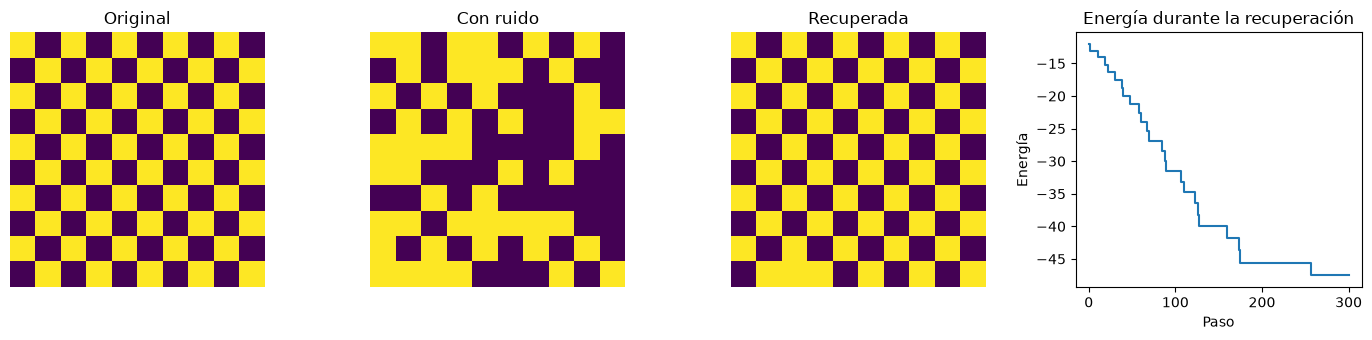

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))

ax[0].imshow(d);                     ax[0].set_title("Original")
ax[1].imshow(s_ruido.reshape(n, m)); ax[1].set_title("Con ruido")
ax[2].imshow(s_rec.reshape(n, m));   ax[2].set_title("Recuperada")
for a in ax[:3]:
    a.axis("off")

ax[3].plot(energias, drawstyle="steps-post")
ax[3].set_xlabel("Paso")
ax[3].set_ylabel("Energía")
ax[3].set_title("Energía durante la recuperación")

plt.tight_layout()
plt.show()

In [50]:
!pip install scikit-image

                                              0.0/11.9 MB ? eta -:--:--
                                             0.0/11.9 MB 640.0 kB/s eta 0:00:19
                                             0.0/11.9 MB 640.0 kB/s eta 0:00:19
                                             0.1/11.9 MB 837.8 kB/s eta 0:00:15
                                              0.2/11.9 MB 1.1 MB/s eta 0:00:11
                                              0.3/11.9 MB 1.4 MB/s eta 0:00:09
                                              0.3/11.9 MB 1.4 MB/s eta 0:00:09
                                              0.3/11.9 MB 1.4 MB/s eta 0:00:09
                                              0.3/11.9 MB 1.4 MB/s eta 0:00:09
     -                                        0.5/11.9 MB 1.3 MB/s eta 0:00:10
     -                                        0.6/11.9 MB 1.2 MB/s eta 0:00:10
     --                                       0.6/11.9 MB 1.3 MB/s eta 0:00:09
     --                                       0.7/11.9 M


[notice] A new release of pip is available: 23.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Imagen real: `camera`

Se carga la foto de ejemplo `camera` de *scikit-image*: una imagen de 512×512 en escala de grises, con valores de 0 (negro) a 255 (blanco). Será el patrón a memorizar en la segunda parte.

(512, 512)


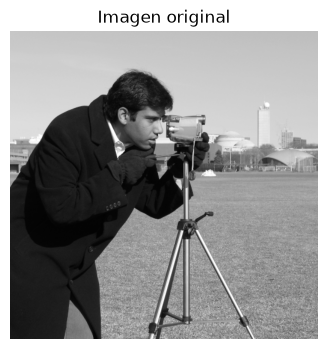

In [8]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data
from skimage.transform import resize
from skimage.color import rgb2gray

img = data.camera()   # imagen 512x512 en escala de grises
print(img.shape)
plt.figure(figsize=(4,4))
plt.imshow(img, cmap="gray")
plt.title("Imagen original")
plt.axis("off")
plt.show()

## Reducir la imagen a 64×64

Se reduce la foto a $64 \times 64$, es decir $N = 4096$ neuronas. Es necesario porque $W$ es de tamaño $N \times N$:
- Con 512×512: $N = 262\,144$, y $W$ mas gasto computacional
- Con 64×64: $N = 4096$, y $W$ menos gasto computacional

(64, 64)


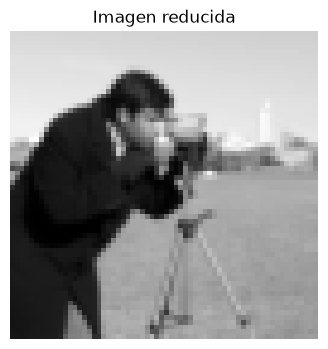

In [103]:
# ============================================================
# Reducir imagen
# ============================================================

n = 64      # número de filas
m = 64      # número de columnas
N = n*m     # número de neuronas

img_small = resize(img, (n, m), anti_aliasing=True)
print(img_small.shape)
plt.figure(figsize=(4,4))
plt.imshow(img_small, cmap="gray")
plt.title("Imagen reducida")
plt.axis("off")
plt.show()

## Binarizar y memorizar la imagen

Como la red solo trabaja con estados $\pm1$, cada píxel se convierte en blanco ($+1$) si es más claro que el brillo promedio, o en negro ($-1$) si es más oscuro. Luego la imagen se aplana en un vector de $N = 4096$ estados y se calcula la matriz de pesos $W$ para memorizarla.

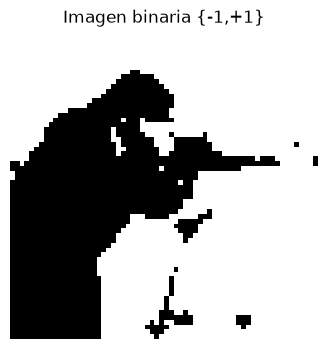

In [117]:
# ============================================================
# Binarización: se debe binarizar para poder usar la red de Hopfield
# ============================================================


# Calcular umbral: lo que esté por encima se considera claro y lo que esté por debajo, oscuro.
threshold = img_small.mean()
# Revisar cada píxel y preguntar si es mayor que 0.506. Si-> blanco (+1). No-> negro(-1)
img_bin = np.where(img_small > threshold, 1, -1)

# Imagen original como vector (1, N)
psi_img = np.concat(img_bin).reshape(1, N)

# Memorizar: matriz de pesos N x N  (tarda unos segundos)
w_ij_img = pesos_ij(psi_img, N)

plt.figure(figsize=(4,4))
plt.imshow(img_bin, cmap="gray")
plt.title("Imagen binaria {-1,+1}")
plt.axis("off")
plt.show()

In [118]:
img_bin

array([[ 1,  1,  1, ...,  1,  1,  1],
       [ 1,  1,  1, ...,  1,  1,  1],
       [ 1,  1,  1, ...,  1,  1,  1],
       ...,
       [-1, -1, -1, ...,  1,  1,  1],
       [-1, -1, -1, ...,  1,  1,  1],
       [-1, -1, -1, ...,  1,  1,  1]], shape=(64, 64))

## Imagen con ruido (30 %)

Se voltea al azar el 30 % de los píxeles de la imagen binaria, unos 1228 de 4096. Este es el estado inicial que la red debe limpiar.

In [123]:
# ============================================================
# Ruido
# ============================================================

def agregar_ruido(s, frac=0.30, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido

frac_ruido = 0.30

s_ruido_img = agregar_ruido(np.concat(img_bin), frac=frac_ruido, seed=123)
s_ruido_img= s_ruido_img.reshape(N, 1)

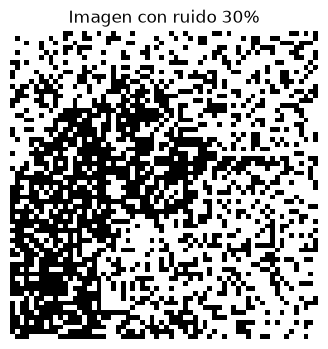

In [124]:
plt.figure(figsize=(4,4))
plt.imshow(s_ruido_img.reshape(n, m), cmap="gray")
plt.title(f"Imagen con ruido {frac_ruido*100:.0f}%")
plt.axis("off")
plt.show()

In [125]:
print("N     =", N)
print("psi   :", psi_img.shape)
print("w_ij  :", w_ij_img.shape)
print("s_rec :", s_ruido_img.shape)

N     = 4096
psi   : (1, 4096)
w_ij  : (4096, 4096)
s_rec : (4096, 1)


## Recuperación de la imagen con ruido

Mismo algoritmo que en el 10×10: se elige un píxel al azar, se calcula su campo local y se actualiza con $\mathrm{sign}(h_i)$. Hay dos cambios:
1. Se hacen unas 10 visitas por píxel en promedio, para que todos los píxeles se revisen.
2. En vez de recalcular $-\frac12 s^TWs$ completa en cada paso (muy costoso con $N = 4096$), se podría solo sumae el cambio:
$$\Delta E = -(s_i^{\text{nuevo}} - s_i^{\text{viejo}})\,h_i$$

In [ ]:
# Recuperación asincrónica aleatoria
# ============================================================
np.random.seed(0)

s_rec_img = s_ruido_img.copy()            # copia: s_ruido queda intacta
energias_img = [energia_s_ruido]      # energía inicial
E = energia_s_ruido               # energía actual

for paso in range(10 * N):        # ~10 visitas por píxel
    # Elegir un píxel al azar
    i = np.random.randint(0, N)

    # Campo local de ese píxel
    h_i = (w_ij[i] @ s_rec).item()

    # Guardar el valor viejo y actualizar (si h_i == 0, no cambia)
    s_viejo = s_rec_img[i, 0]
    if h_i > 0:
        s_rec_img[i] = 1
    elif h_i < 0:
        s_rec_img[i] = -1

    # Actualizar la energía solo con el cambio ΔE
    E = E - (s_rec_img[i, 0] - s_viejo) * h_i
    energias_img.append(E)

print("Energía inicial:", energias_img[0])
print("Energía final:  ", energias_img[-1])
print("Píxeles incorrectos:", np.sum(s_rec_img.flatten() != psi_img[0]))

Energía inicial: -1200.0
Energía final:   -4031496.0
Píxeles incorrectos: 0


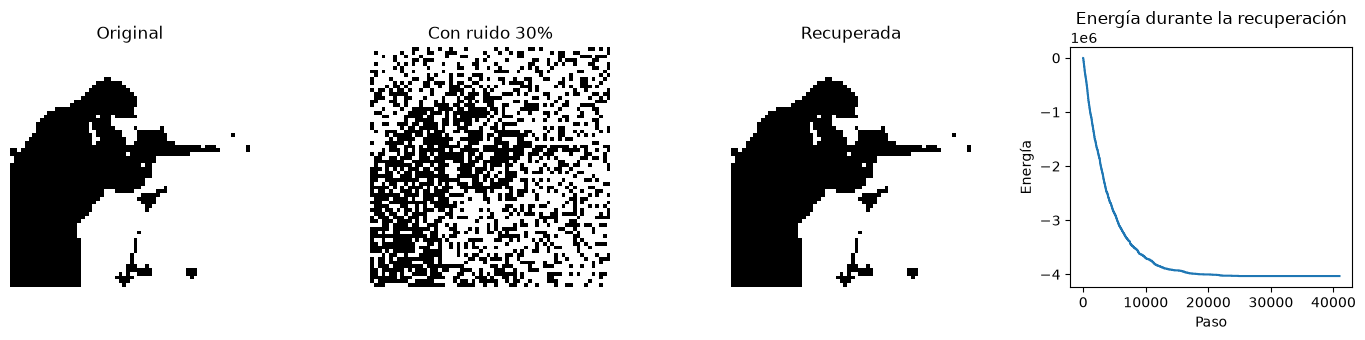

In [ ]:
# Resultados
# ============================================================
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))

ax[0].imshow(img_bin, cmap="gray")
ax[0].set_title("Original")

ax[1].imshow(s_ruido_img.reshape(n, m), cmap="gray")
ax[1].set_title(f"Con ruido {frac_ruido*100:.0f}%")

ax[2].imshow(s_rec_img.reshape(n, m), cmap="gray")
ax[2].set_title("Recuperada")

for a in ax[:3]:
    a.axis("off")

ax[3].plot(energias_img)
ax[3].set_xlabel("Paso")
ax[3].set_ylabel("Energía")
ax[3].set_title("Energía durante la recuperación")

plt.tight_layout()
plt.show()